# Scraping de todos los equipos — corrida post-fecha

Baja los partidos de **todos los rivales de la temporada** (no solo el próximo), reutilizando
exactamente las mismas funciones del pre-partido: `scrape_rival_recent` y `scrape_rival_managers`.

**Cuándo correrlo:** una vez terminada cada fecha. Como el scraper es incremental (los partidos que
ya están completos se saltean sin llamadas de red), cada corrida solo baja lo nuevo de la fecha.

**Para qué:** tener los datos de todos los equipos ya en disco, así el análisis pre-partido no tiene
que esperar el scraping del rival de turno y se pueden armar estadísticas comparativas de la liga.

**Qué baja de cada partido:** lo mismo que un partido de For Ever — los 9 endpoints crudos
(`event`, `statistics`, `lineups`, `incidents`, `shotmap`, `average_positions`, `graph`,
`best_players`, `heatmaps`) más el DT (`managers`), y los 9 CSV limpios, con el lineups ya
enriquecido con cambios y tarjetas.

Las pausas entre requests son las de siempre: `config.MIN_DELAY`–`config.MAX_DELAY` segundos.

> **Ojo con la primera corrida.** Los equipos que están en cero arrancan de ~19 partidos cada uno,
> y cada partido son 8 requests + ~22 de heatmaps. Son varias horas. De ahí en adelante, cada
> corrida post-fecha es solo un partido nuevo por equipo.


In [8]:
import os, sys, time, random

%load_ext autoreload
%autoreload 2

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import config
from src.scraping.rivals_scraper import (
    scrape_rival_recent, scrape_rival_managers, rival_already_scraped,
)

# ============================================================
# CONFIGURAR ACÁ
SEASON   = '2026'
EQUIPOS  = list(config.RIVALS_2026)   # los 18 rivales de la temporada
CON_DT   = True                       # bajar tambien el DT de cada partido (/managers)
HEATMAPS = True                       # mapas de calor por jugador (~22 requests extra por partido)
HEADLESS = False                      # False = con ventana, igual que el pre-partido
# ============================================================

print(f'Temporada {SEASON} · {len(EQUIPOS)} equipos')
print(f'Pausa entre requests: {config.MIN_DELAY}-{config.MAX_DELAY} s')
for s in EQUIPOS:
    print(f'  · {s:26s} {config.RIVALS[s]["name"]}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Temporada 2026 · 18 equipos
Pausa entre requests: 6-12 s
  · acassuso                   Acassuso
  · all_boys                   All Boys
  · almirante_brown            Almirante Brown
  · central_norte              Central Norte de Salta
  · ciudad_de_bolivar          Ciudad de Bolívar
  · colon                      Club Atlético Colón
  · defensores_de_belgrano     Defensores de Belgrano
  · deportivo_madryn           Deportivo Madryn
  · deportivo_moron            Deportivo Morón
  · estudiantes_caseros        Estudiantes de Buenos Aires
  · ferro_carril_oeste         Club Ferro Carril Oeste
  · gimnasia_de_jujuy          Gimnasia Jujuy
  · godoy_cruz                 Godoy Cruz
  · los_andes                  Los Andes
  · mitre                      CA Mitre
  · racing_de_cordoba          Racing de Córdoba
  · san_miguel                 San Miguel
  · san_telmo                  San Telmo


## 1. Qué falta bajar

Antes de disparar nada, mirá cuántos partidos hay ya en disco por equipo.


In [9]:
from src.scraping.chaco_scraper import _match_done

def partidos_en_disco(slug, season=SEASON):
    """(completos, incompletos). Completo = mismo criterio que el scraper de Chaco.
    Los partidos bajados con la version vieja del scraper cuentan como incompletos:
    les faltan event/average_positions/momentum/best_players/heatmaps y se vuelven
    a bajar enteros en la proxima corrida."""
    d = os.path.join(config.rivals_dir(season), slug)
    if not os.path.isdir(d):
        return 0, 0
    dirs = [os.path.join(d, m) for m in os.listdir(d) if os.path.isdir(os.path.join(d, m))]
    ok = sum(1 for m in dirs if _match_done(m))
    return ok, len(dirs) - ok

print(f'{"EQUIPO":28s} {"COMPLETOS":>9s} {"A REBAJAR":>9s}')
for slug in EQUIPOS:
    ok, falta = partidos_en_disco(slug)
    print(f'{config.RIVALS[slug]["name"]:28s} {ok:>9d} {falta:>9d}')


EQUIPO                       COMPLETOS A REBAJAR
Acassuso                            19         1
All Boys                            19         1
Almirante Brown                     20         0
Central Norte de Salta              19         1
Ciudad de Bolívar                   20         0
Club Atlético Colón                 19         1
Defensores de Belgrano              20         0
Deportivo Madryn                    18         2
Deportivo Morón                     18         2
Estudiantes de Buenos Aires         19         1
Club Ferro Carril Oeste             19         1
Gimnasia Jujuy                      18         2
Godoy Cruz                          20         0
Los Andes                           20         0
CA Mitre                            19         1
Racing de Córdoba                   19         1
San Miguel                          20         0
San Telmo                           20         0


## 2. Scraping de todos los equipos

Loop sobre los equipos llamando a las mismas funciones del pre-partido. `n_matches=None` baja
**todos** los partidos jugados de la temporada, que es lo que el pre-partido necesita para que
formaciones, mejor once y disciplina salgan sobre la muestra completa.

Es reanudable: si se corta a mitad, volvés a correr la celda y sigue donde estaba.


In [10]:
resumen = {}
fallidos = {}
sep = '=' * 70

for i, slug in enumerate(EQUIPOS, 1):
    nombre = config.RIVALS[slug]['name']
    print(f'\n{sep}\n[{i}/{len(EQUIPOS)}] {nombre}  ({slug})\n{sep}')
    try:
        mks = scrape_rival_recent(slug, n_matches=None, season=SEASON,
                                  headless=HEADLESS, include_heatmaps=HEATMAPS)
        if CON_DT:
            scrape_rival_managers(slug, season=SEASON, headless=HEADLESS)
        resumen[slug] = len(mks)
    except Exception as e:
        fallidos[slug] = repr(e)
        print(f'  ERROR en {nombre}: {e}')

    # Misma pausa que el scraper usa entre partidos, ahora entre equipos.
    if i < len(EQUIPOS):
        time.sleep(random.uniform(config.MIN_DELAY, config.MAX_DELAY))

print(f'\n\nListo. {len(resumen)}/{len(EQUIPOS)} equipos ok.')
if fallidos:
    print('Fallidos (volvé a correr la celda: arranca donde quedó):')
    for slug, err in fallidos.items():
        print(f'  · {slug}: {err}')



[1/18] Acassuso  (acassuso)
Scrapeando TODOS los partidos de Acassuso en la temporada 2026 (id=112491)...
  Encontrados 20 partidos en Primera Nacional.

  [1/20] Ya existe: 2026-02-14_vs_chaco_for_ever_h
  [2/20] Ya existe: 2026-02-21_vs_racing_de_cordoba_h
  [3/20] Ya existe: 2026-03-01_vs_san_telmo_a
  [4/20] Ya existe: 2026-03-14_vs_club_atletico_colon_a
  [5/20] Ya existe: 2026-03-21_vs_deportivo_moron_h
  [6/20] Ya existe: 2026-04-04_vs_godoy_cruz_a
  [7/20] Ya existe: 2026-04-08_vs_ferrocarril_midland_a
  [8/20] Ya existe: 2026-04-12_vs_los_andes_h
  [9/20] Ya existe: 2026-04-18_vs_all_boys_a
  [10/20] Ya existe: 2026-04-26_vs_estudiantes_de_buenos_air_h
  [11/20] Ya existe: 2026-05-03_vs_ca_mitre_a
  [12/20] Ya existe: 2026-05-10_vs_almirante_brown_h
  [13/20] Ya existe: 2026-05-16_vs_ciudad_de_bolivar_a
  [14/20] Ya existe: 2026-05-24_vs_defensores_de_belgrano_h
  [15/20] Ya existe: 2026-05-31_vs_deportivo_madryn_a
  [16/20] Ya existe: 2026-06-06_vs_central_norte_de_salta_h
 

KeyboardInterrupt: 

## 3. Control final

Cuántos partidos quedó con cada equipo. Corriendo esto después de cada fecha, el número debería
subir de a uno por equipo.


In [ ]:
ARCHIVOS = ['event_clean.csv', 'statistics_clean.csv', 'lineups_clean.csv',
            'incidents_clean.csv', 'shotmap_clean.csv', 'average_positions_clean.csv',
            'momentum_clean.csv', 'best_players_clean.csv', 'player_heatmaps_clean.csv']

print(f'{"EQUIPO":28s} {"COMPLETOS":>9s} {"HEATMAP":>7s} {"DT":>4s}')
total = 0
for slug in EQUIPOS:
    d = os.path.join(config.rivals_dir(SEASON), slug)
    ok, _ = partidos_en_disco(slug)
    hm = dt = 0
    if os.path.isdir(d):
        for m in os.listdir(d):
            mp = os.path.join(d, m)
            hm += os.path.exists(os.path.join(mp, 'player_heatmaps_clean.csv'))
            dt += os.path.exists(os.path.join(mp, 'raw', 'managers.json'))
    total += ok
    print(f'{config.RIVALS[slug]["name"]:28s} {ok:>9d} {hm:>7d} {dt:>4d}')
print(f'\nTotal de partidos de rivales completos: {total}')

# Chequeo fino: que ningun partido completo se haya quedado sin alguno de los 9 CSV.
faltantes = []
for slug in EQUIPOS:
    d = os.path.join(config.rivals_dir(SEASON), slug)
    if not os.path.isdir(d):
        continue
    for m in sorted(os.listdir(d)):
        mp = os.path.join(d, m)
        falta = [f for f in ARCHIVOS if not os.path.exists(os.path.join(mp, f))]
        if falta:
            faltantes.append((slug, m, falta))
if faltantes:
    print(f'\n{len(faltantes)} partidos con archivos faltantes:')
    for slug, m, falta in faltantes[:20]:
        print(f'  · {slug}/{m}: {", ".join(falta)}')
else:
    print('Todos los partidos tienen los 9 CSV.')


EQUIPO                       COMPLETOS HEATMAP   DT
Acassuso                            19      19   20
All Boys                            19      20   20
Almirante Brown                     20      20   20
Central Norte de Salta              19      19   20
Ciudad de Bolívar                   20      20   20
Club Atlético Colón                 19      19   20
Defensores de Belgrano              20      20   20
Deportivo Madryn                    18      18   20
Deportivo Morón                     18      18   20
Estudiantes de Buenos Aires         19      19   20
Club Ferro Carril Oeste             19      19   20
Gimnasia Jujuy                      18      18   20
Godoy Cruz                          20      20   20
Los Andes                           20      20   20
CA Mitre                            19      19   20
Racing de Córdoba                   19      19   20
San Miguel                          20      20   20
San Telmo                           20      20   20

Total de pa

## 4. Análisis de temporada de cada rival

Las funciones de `analisis_temporada.ipynb` son genéricas: toman `match_keys` + `base_dir` y sacan la
perspectiva del equipo del sufijo `_h`/`_a` del match_key. Como los match_keys del rival están armados
desde SU óptica, corriendo lo mismo apuntando a `data/temporadas/{season}/rivals/{slug}/` sale el
análisis de temporada del rival, tal cual el nuestro (las columnas `chaco_*` de las tablas se leen
como "el equipo analizado").

Los gráficos van a `outputs/temporadas/{season}/rivals/{slug}/graficos/`.


In [ ]:
import matplotlib
matplotlib.use('Agg')
import pandas as pd
from IPython.display import Image, display

from src.analysis.season import (
    build_season_table, season_stats, season_player_stats,
    top_scorers, most_used_players,
    threat_by_situation, markov_game_state, goals_by_time_window,
    is_home_match,
)
from src.visualization.season import (
    save_fig, plot_season_points, plot_xg_season, plot_top_players,
    plot_shotmap_4grid, plot_recent_form, plot_home_away_panel,
    plot_discipline, plot_threat_by_situation, plot_markov_transitions,
    plot_goals_by_time_window,
)

RATING_MIN_MIN = 450   # minutos minimos para el top de rating

def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

def match_keys_rival(slug, season=SEASON):
    """Partidos completos del rival, en orden cronologico."""
    d = config.rival_data_dir(slug, season)
    if not os.path.isdir(d):
        return []
    return sorted(m for m in os.listdir(d) if _match_done(os.path.join(d, m)))

def analisis_temporada_equipo(slug, season=SEASON, graficos=True):
    """Analisis de temporada del rival, con las MISMAS funciones que el de For Ever.

    Devuelve (stats, season_df, player_df). Ojo: las columnas 'chaco_goals' /
    'chaco_xg' de las tablas se leen como "el equipo analizado" — el match_key del
    rival esta armado desde su optica, asi que is_home_match() resuelve bien de que
    lado mirar cada partido.

    Graficos -> outputs/temporadas/{season}/rivals/{slug}/graficos/
    """
    nombre   = config.RIVALS[slug]['name']
    base_dir = config.rival_data_dir(slug, season)
    mks      = match_keys_rival(slug, season)
    if not mks:
        print(f'{nombre}: sin partidos completos, se saltea.')
        return None, None, None

    season_df = build_season_table(mks, base_dir)
    stats     = season_stats(season_df)
    player_df = season_player_stats(mks, base_dir)

    if not graficos:
        return stats, season_df, player_df

    plots_dir = config.rival_plots_dir(slug, season)
    os.makedirs(plots_dir, exist_ok=True)
    p = lambda f: os.path.join(plots_dir, f)

    save_fig(plot_season_points(season_df), p('puntos_acumulados.png'))

    fig = plot_xg_season(season_df)
    if fig:
        save_fig(fig, p('xg_temporada.png'))

    plot_recent_form(season_df, window=5, season=season, save_path=p('forma_reciente.png'))
    plot_home_away_panel(season_df, season=season, save_path=p('local_visitante.png'))

    if not player_df.empty:
        save_fig(plot_top_players(player_df, metric='minutos', top_n=15), p('top_minutos.png'))

        rating_df = player_df[player_df['minutos'] >= RATING_MIN_MIN].dropna(subset=['rating_promedio'])
        if not rating_df.empty:
            xmin = max(4.0, float(rating_df['rating_promedio'].min()) - 0.3)
            save_fig(plot_top_players(rating_df, metric='rating_promedio', top_n=15, xmin=xmin),
                     p('top_rating.png'))

        plot_discipline(player_df, season=season, save_path=p('disciplina.png'))

    # Shotmap acumulado: solo los remates del equipo analizado
    shots = []
    for mk in mks:
        sp = os.path.join(base_dir, mk, 'shotmap_clean.csv')
        if os.path.exists(sp):
            df_s = pd.read_csv(sp)
            shots.append(df_s[df_s['isHome'] == is_home_match(mk)])
    if shots:
        df_shots = pd.concat(shots, ignore_index=True)
        save_fig(plot_shotmap_4grid(df_shots, team_label=nombre,
                                    title=f'Distribucion de Tiros - {nombre} {season}'),
                 p('shotmap_temporada.png'))

    # Los mismos analisis finos que le corremos al Negro
    thr = threat_by_situation(mks, base_dir)
    if thr is not None and not thr.empty:
        plot_threat_by_situation(thr, season=season, save_path=p('amenaza_por_situacion.png'))

    matrix_df, transitions_df = markov_game_state(mks, base_dir)
    if matrix_df is not None and not matrix_df.empty:
        plot_markov_transitions(matrix_df, transitions_df, season=season,
                                save_path=p('markov_estado_marcador.png'))

    win_df = goals_by_time_window(mks, base_dir)
    if win_df is not None and not win_df.empty:
        plot_goals_by_time_window(win_df, season=season, save_path=p('goles_por_ventana.png'))

    return stats, season_df, player_df

print('analisis_temporada_equipo() listo.')


analisis_temporada_equipo() listo.


In [ ]:
# Corre el analisis de temporada de los 18 equipos y arma la tabla comparativa de la liga.
# Es solo lectura de disco + graficos: no toca la red, se puede repetir cuantas veces quieras.
temporadas = {}
filas = []

for slug in EQUIPOS:
    nombre = config.RIVALS[slug]['name']
    stats, season_df, player_df = analisis_temporada_equipo(slug, SEASON)
    if not stats:
        continue
    temporadas[slug] = {'stats': stats, 'season_df': season_df, 'player_df': player_df}
    filas.append({
        'equipo': nombre,
        'PJ':  stats['partidos'],
        'V':   stats['victorias'],
        'E':   stats['empates'],
        'D':   stats['derrotas'],
        'Pts': stats['puntos'],
        'GF':  stats['goles_favor'],
        'GC':  stats['goles_contra'],
        'DG':  stats['diferencia_goles'],
        'xGF': stats['xg_favor'],
        'xGC': stats['xg_contra'],
        'local':      stats['rendimiento_local'],
        'visitante':  stats['rendimiento_visitante'],
    })
    print(f"OK {nombre:28s} {stats['partidos']:>2d} PJ | {stats['puntos']:>2d} pts | "
          f"{stats['goles_favor']}-{stats['goles_contra']}")

liga = pd.DataFrame(filas).sort_values(['Pts', 'DG', 'GF'], ascending=False).reset_index(drop=True)
liga.index += 1
print('\n=== La liga segun nuestros propios datos ===')
print(liga.to_string())

liga_csv = os.path.join(config.OUTPUTS_DIR, 'temporadas', SEASON, 'rivals', 'liga_resumen.csv')
os.makedirs(os.path.dirname(liga_csv), exist_ok=True)
liga.to_csv(liga_csv, index=False, encoding='utf-8')
print(f'\nGuardado: {liga_csv}')


OK Acassuso                     19 PJ | 19 pts | 12-20
OK All Boys                     19 PJ | 20 pts | 12-19
OK Almirante Brown              20 PJ | 30 pts | 15-13
OK Central Norte de Salta       19 PJ | 19 pts | 12-17
OK Ciudad de Bolívar            20 PJ | 30 pts | 19-16
OK Club Atlético Colón          19 PJ | 32 pts | 23-15
OK Defensores de Belgrano       20 PJ | 23 pts | 14-18
OK Deportivo Madryn             18 PJ | 27 pts | 24-19
OK Deportivo Morón              18 PJ | 33 pts | 26-16
OK Estudiantes de Buenos Aires  19 PJ | 30 pts | 18-15
OK Club Ferro Carril Oeste      19 PJ | 37 pts | 22-14
OK Gimnasia Jujuy               18 PJ | 35 pts | 30-18
OK Godoy Cruz                   20 PJ | 28 pts | 20-17
OK Los Andes                    20 PJ | 32 pts | 19-8
OK CA Mitre                     19 PJ | 15 pts | 18-27
OK Racing de Córdoba            19 PJ | 21 pts | 17-21
OK San Miguel                   20 PJ | 25 pts | 17-21
OK San Telmo                    20 PJ | 20 pts | 16-21

=== La lig

## 5. Un equipo en detalle

Poné el slug del próximo rival y mirá su temporada acá mismo: tabla, goleadores, más utilizados y los
gráficos que se acaban de generar. Con esto el pre-partido arranca con la mitad del trabajo hecho.


=== San Miguel · Temporada 2026 ===
20 PJ | 5V-10E-5D | 25 pts
Goles: 17 a favor / 21 en contra
xG: 17.36 favor / 20.74 contra
Local: 4V-3E-3D  |  Visitante: 1V-7E-2D

      date                  opponent     venue result  goles  goles_rival
2026-02-13    Central Norte De Salta     Local      W      1            0
2026-02-21   Club Ferro Carril Oeste Visitante      D      1            1
2026-02-28            Chaco For Ever     Local      W      2            0
2026-03-14                 San Telmo     Local      D      1            1
2026-03-21         Racing De Cordoba     Local      L      1            2
2026-03-28                Colegiales Visitante      D      0            0
2026-04-04       Club Atletico Colon Visitante      L      0            3
2026-04-11           Deportivo Moron     Local      W      2            1
2026-04-18                Godoy Cruz Visitante      D      0            0
2026-04-25                 Los Andes     Local      L      0            2
2026-04-30        

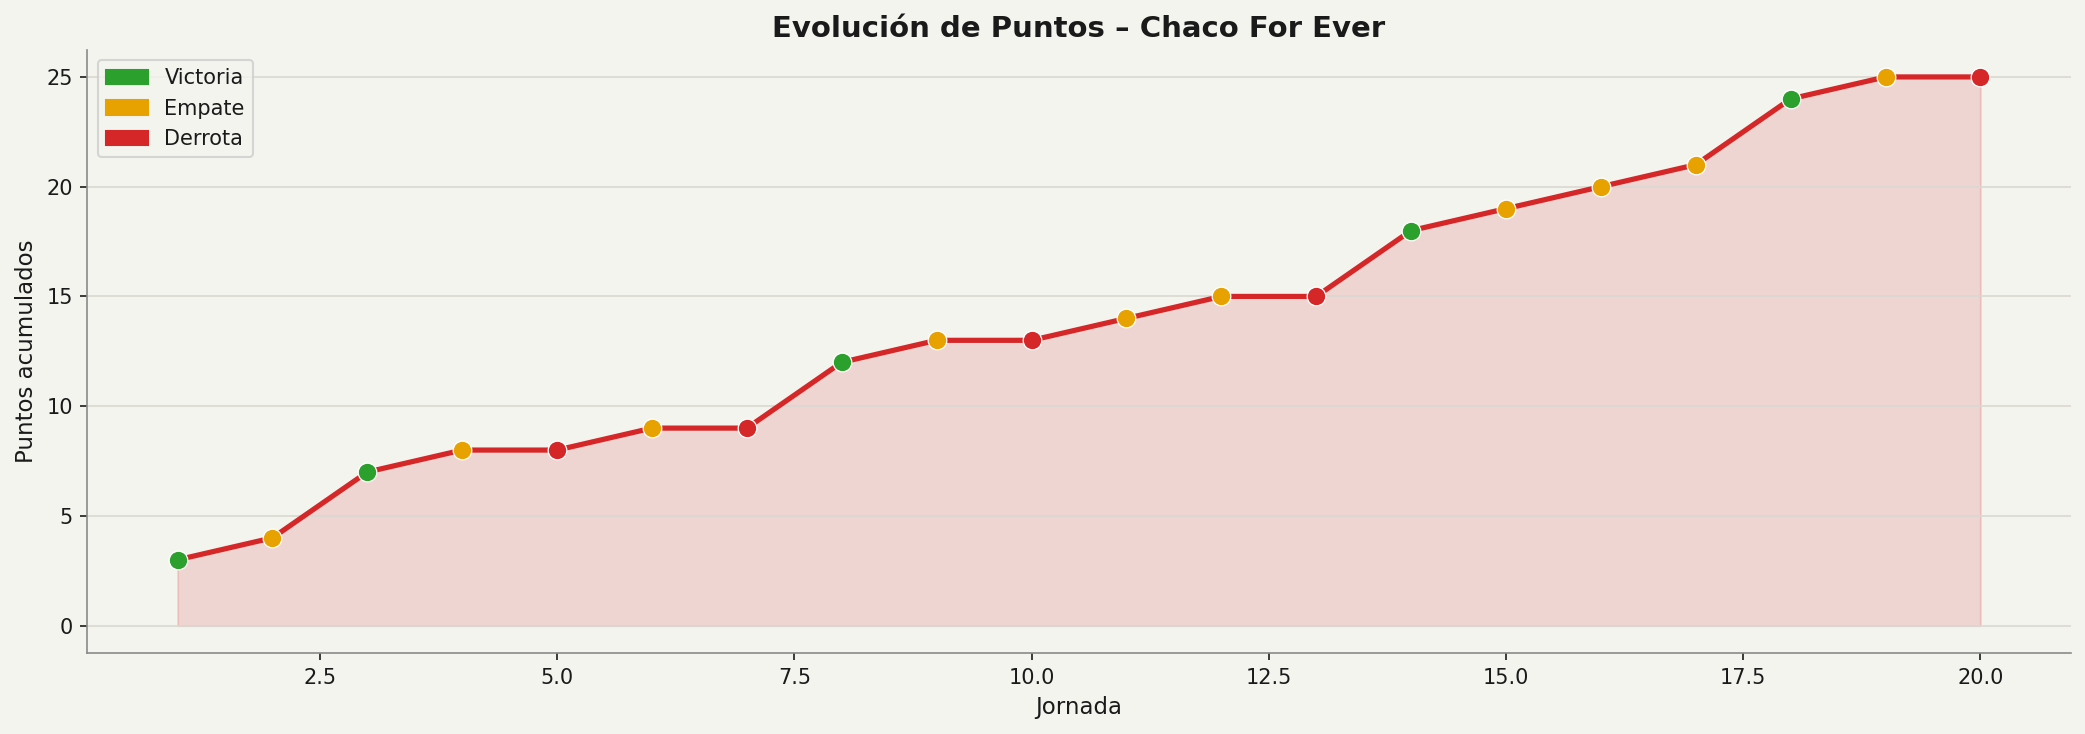

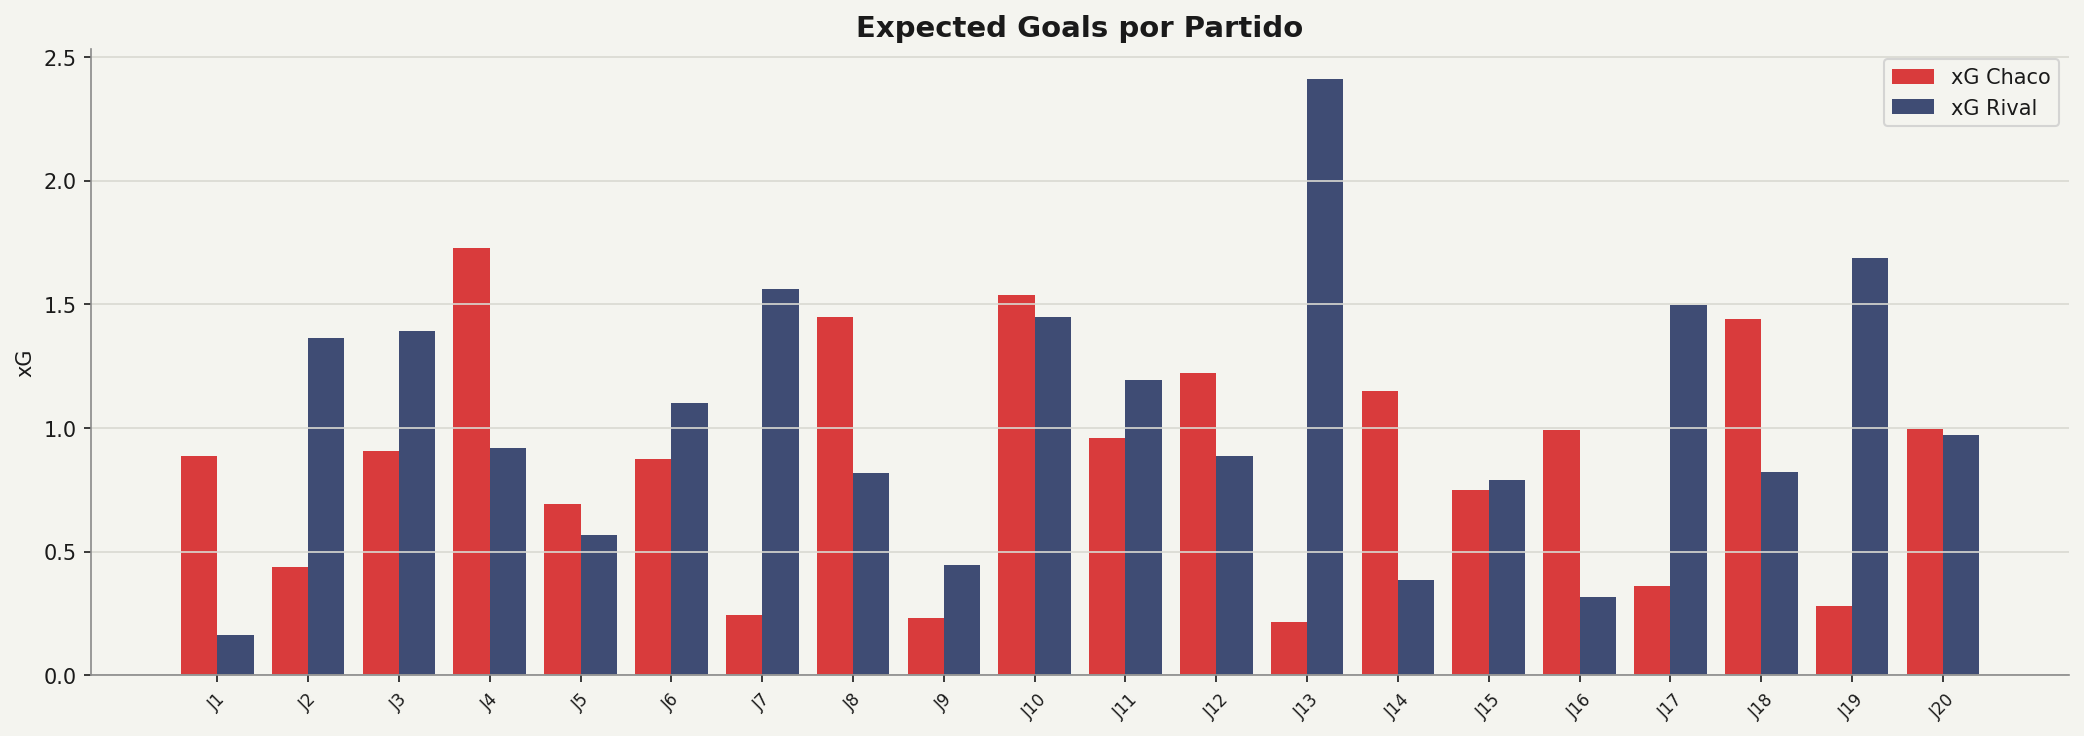

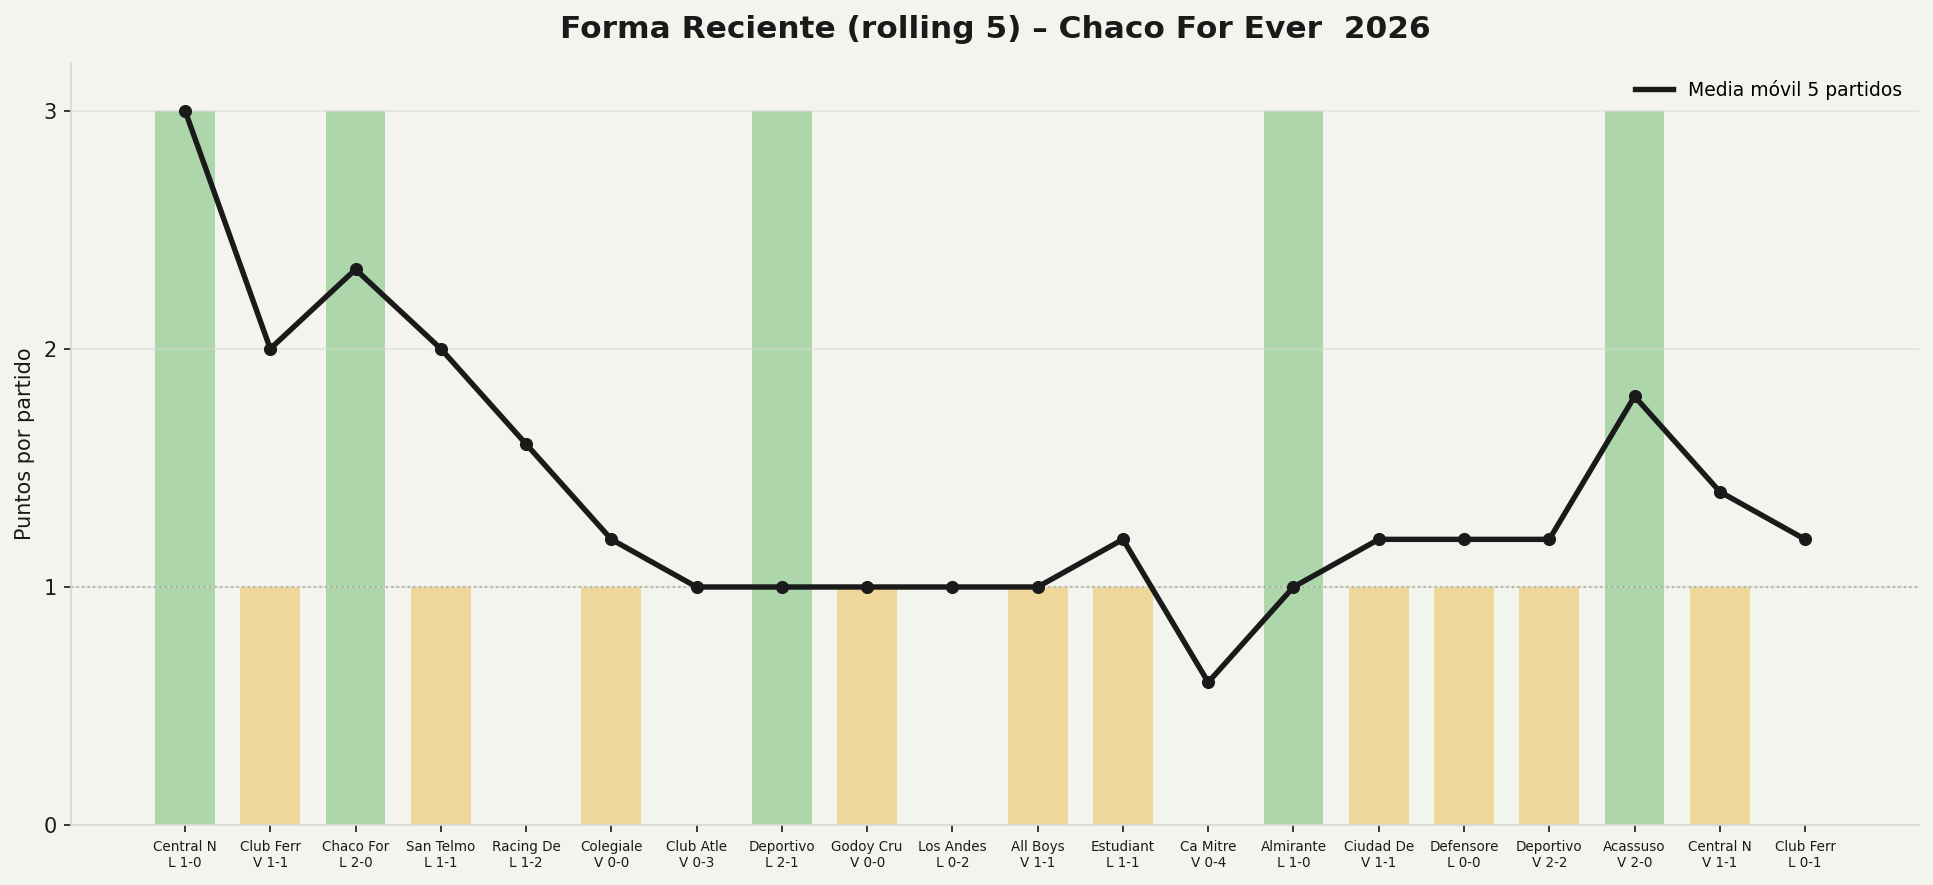

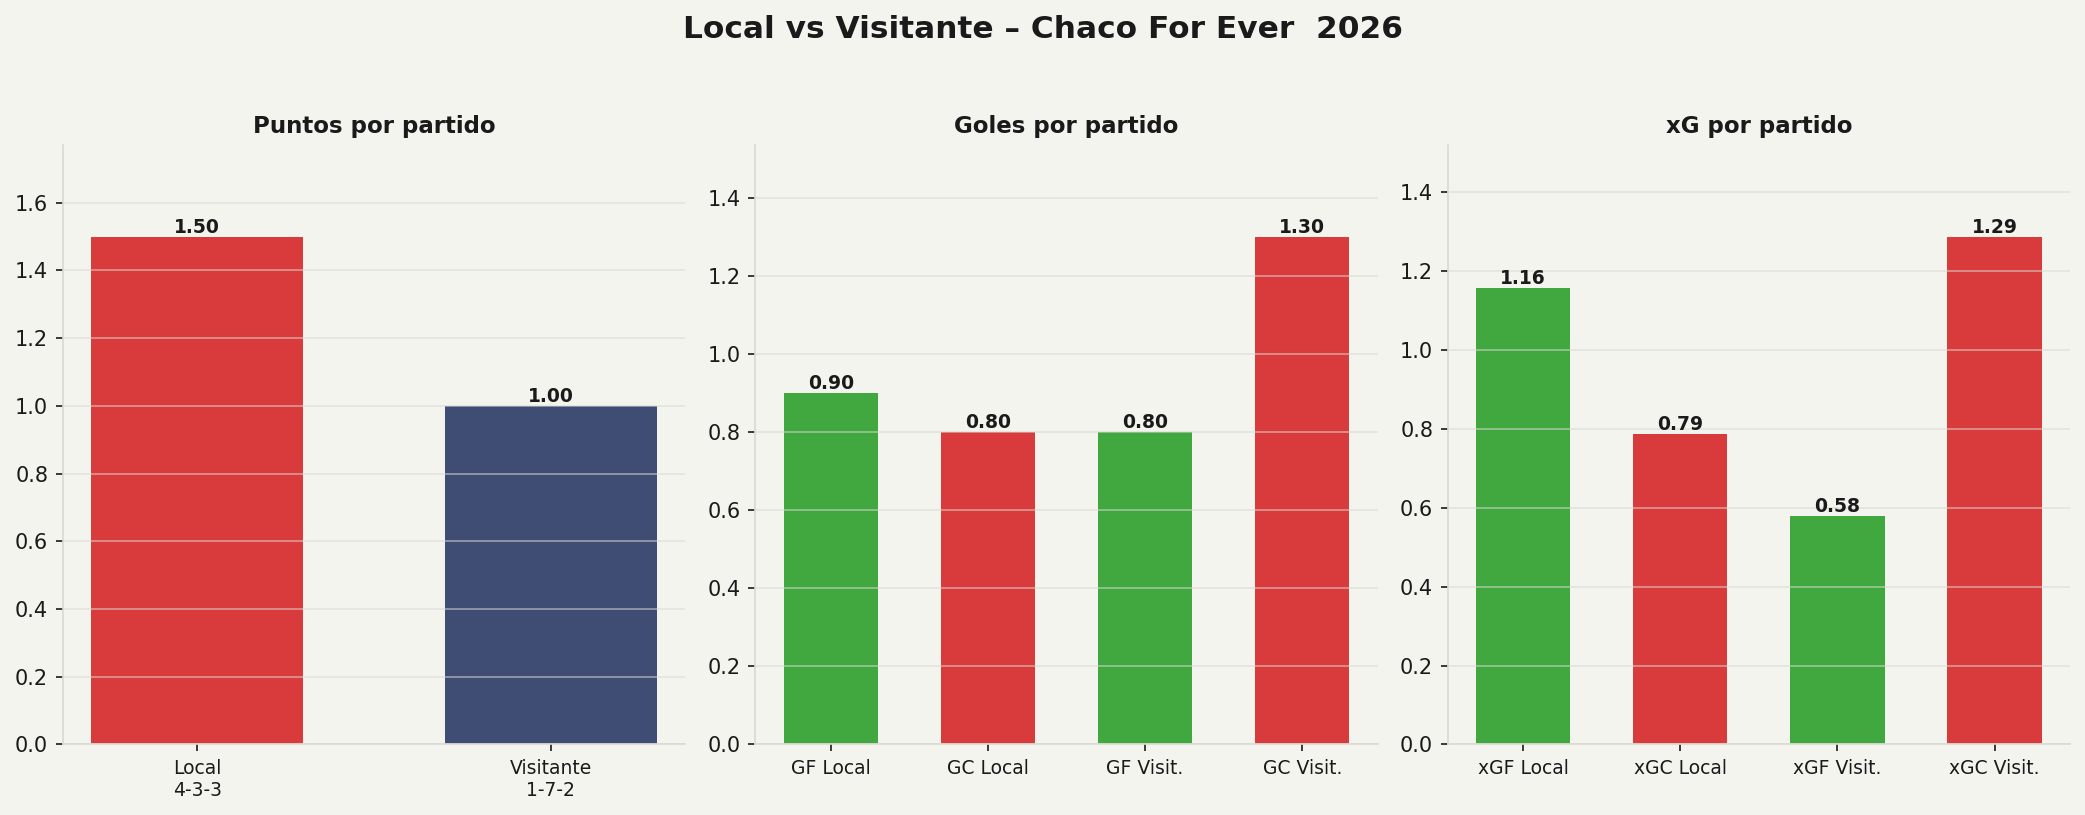

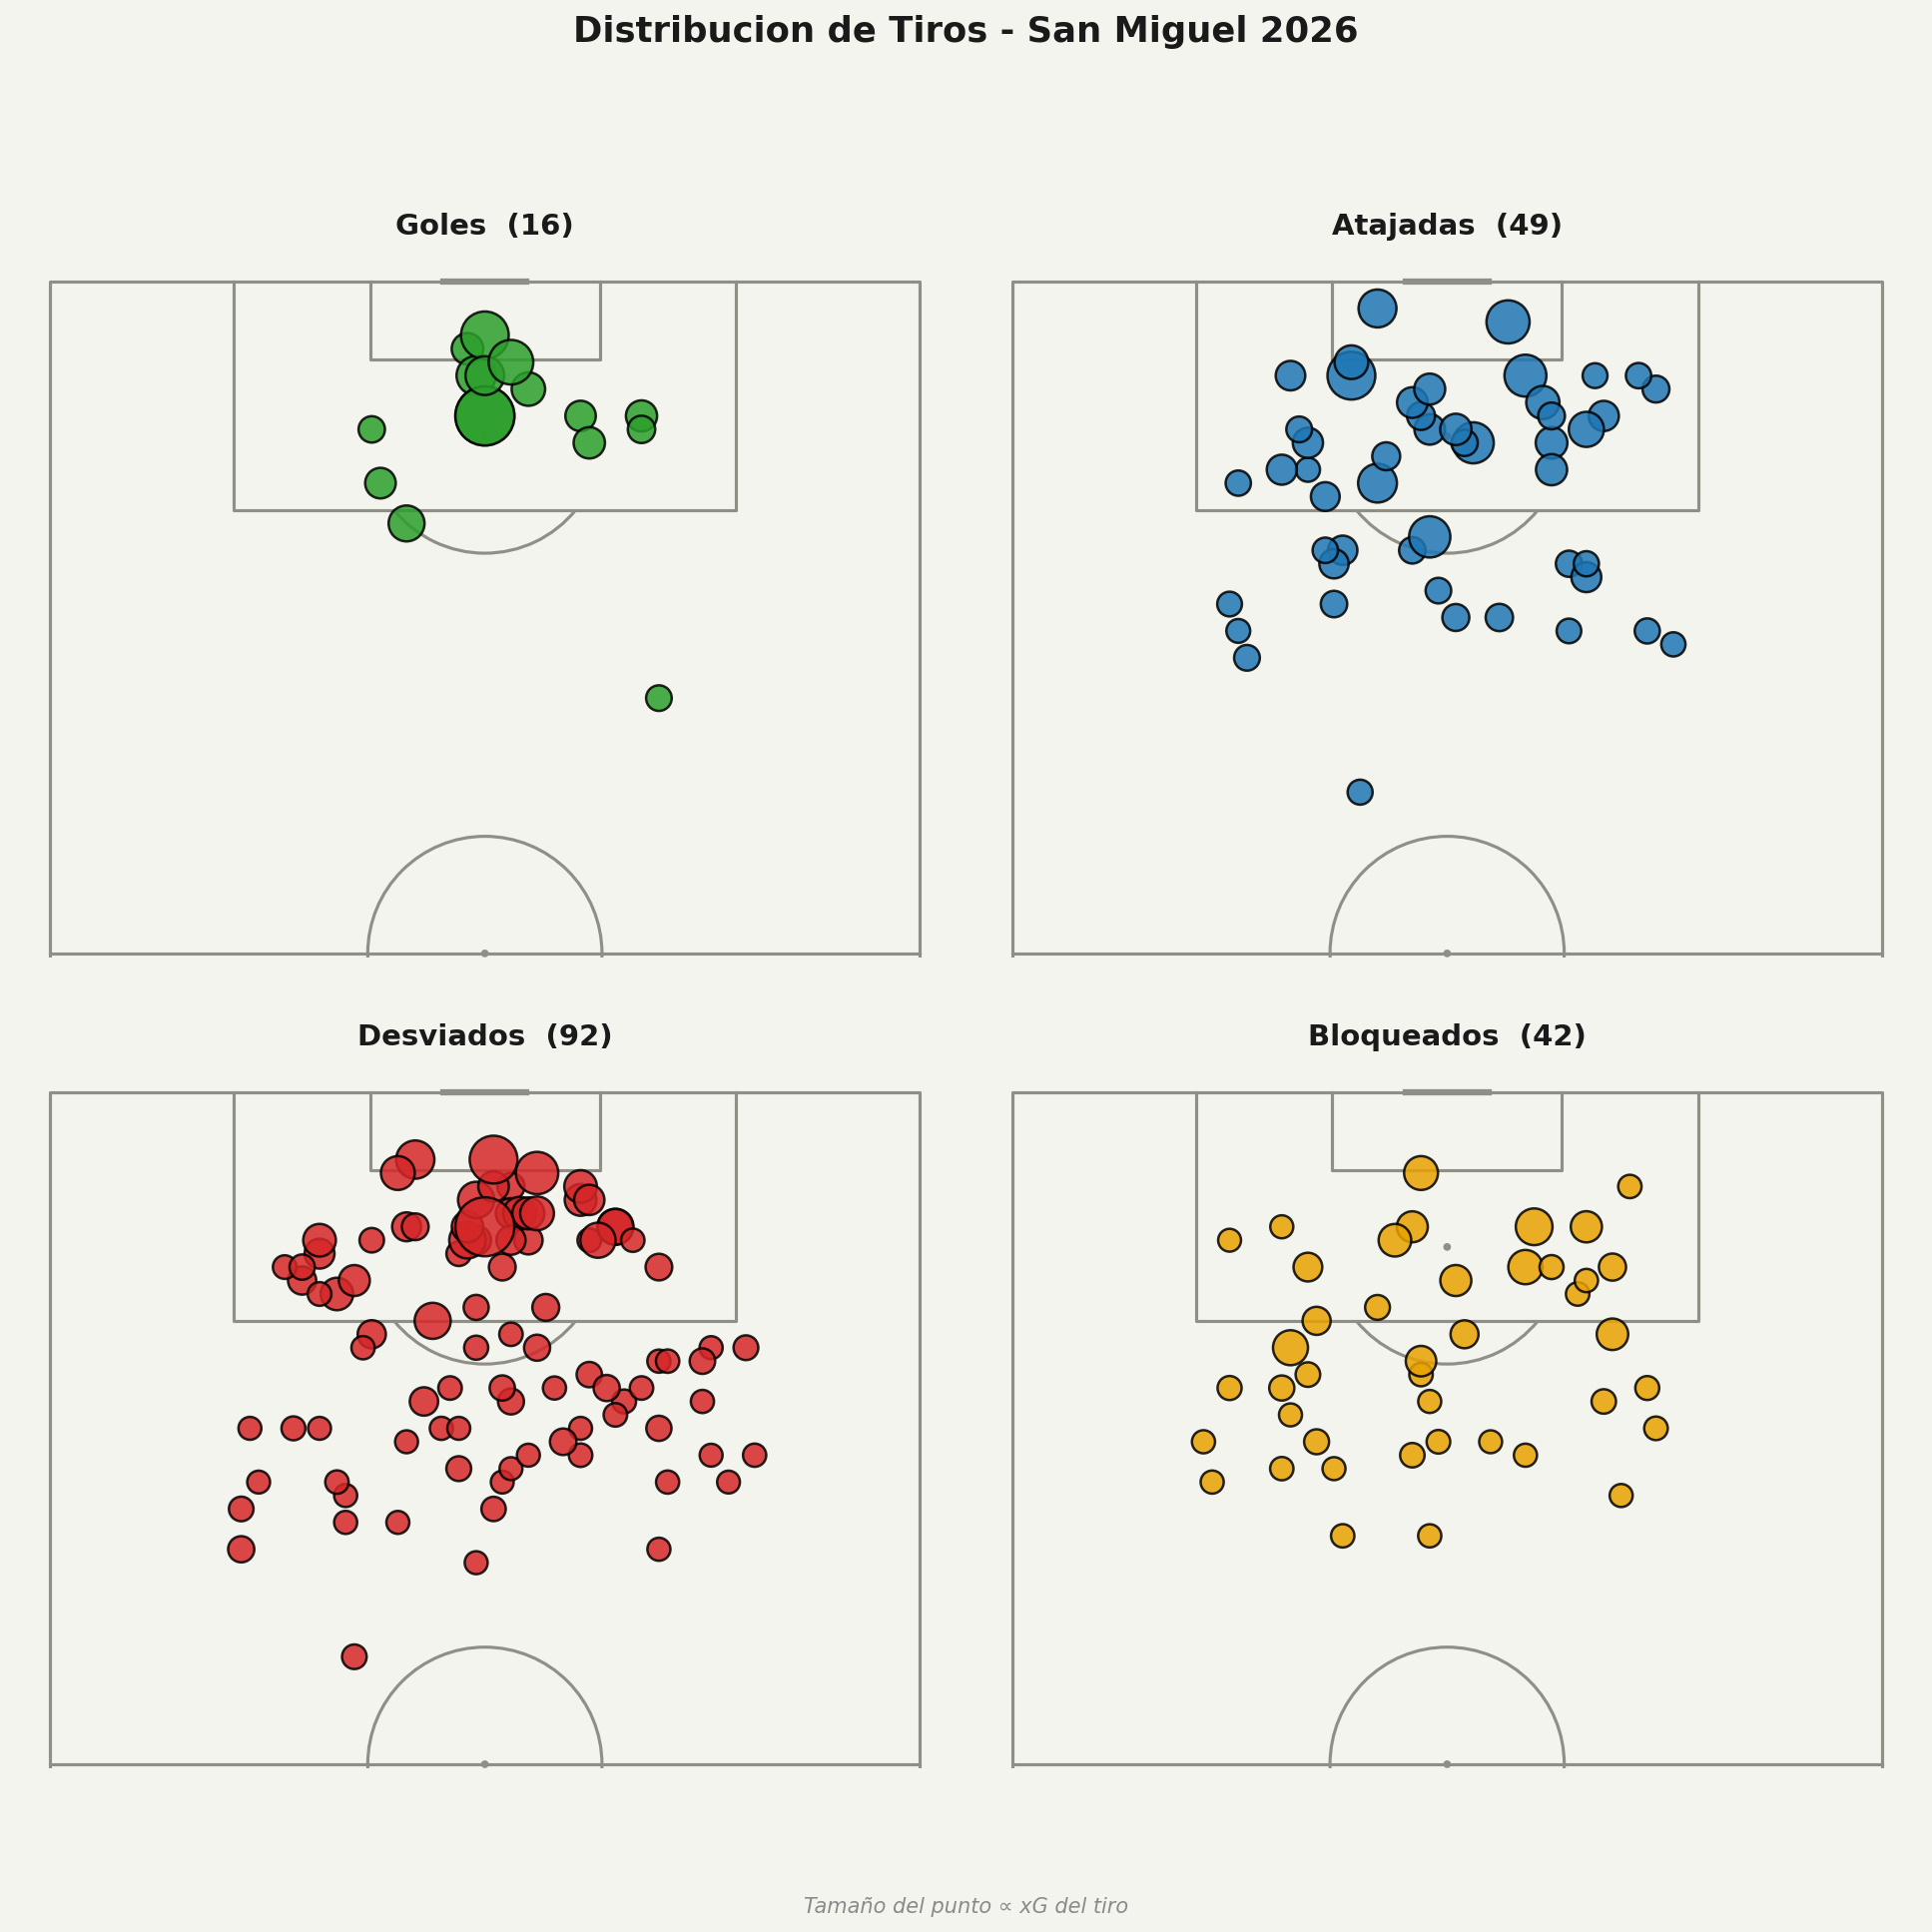

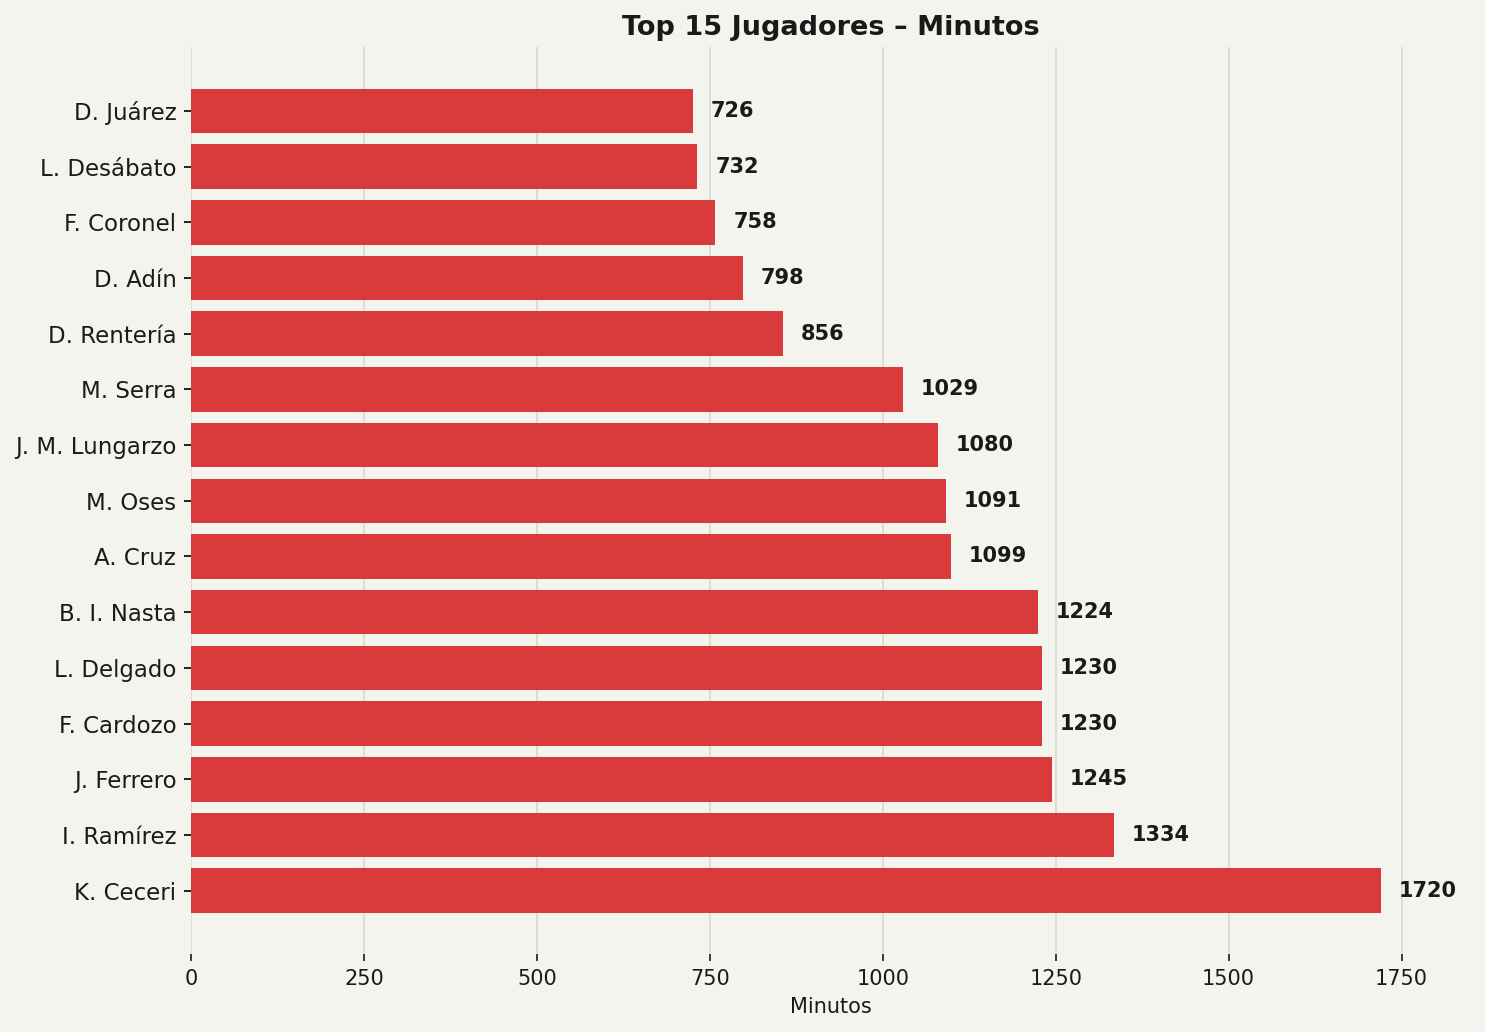

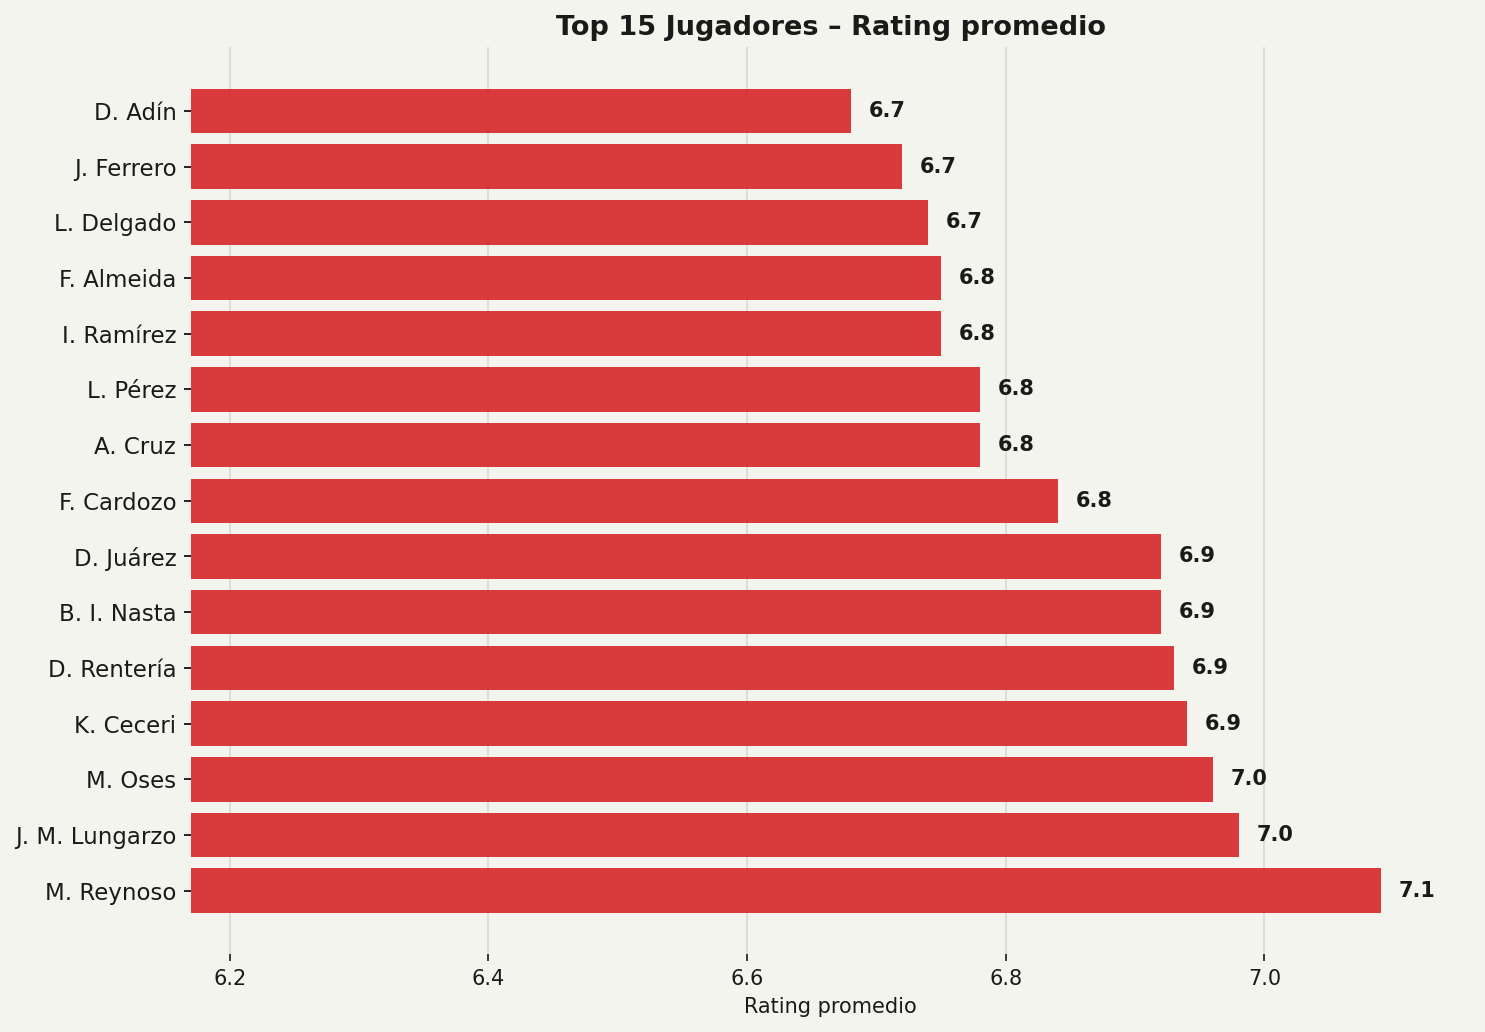

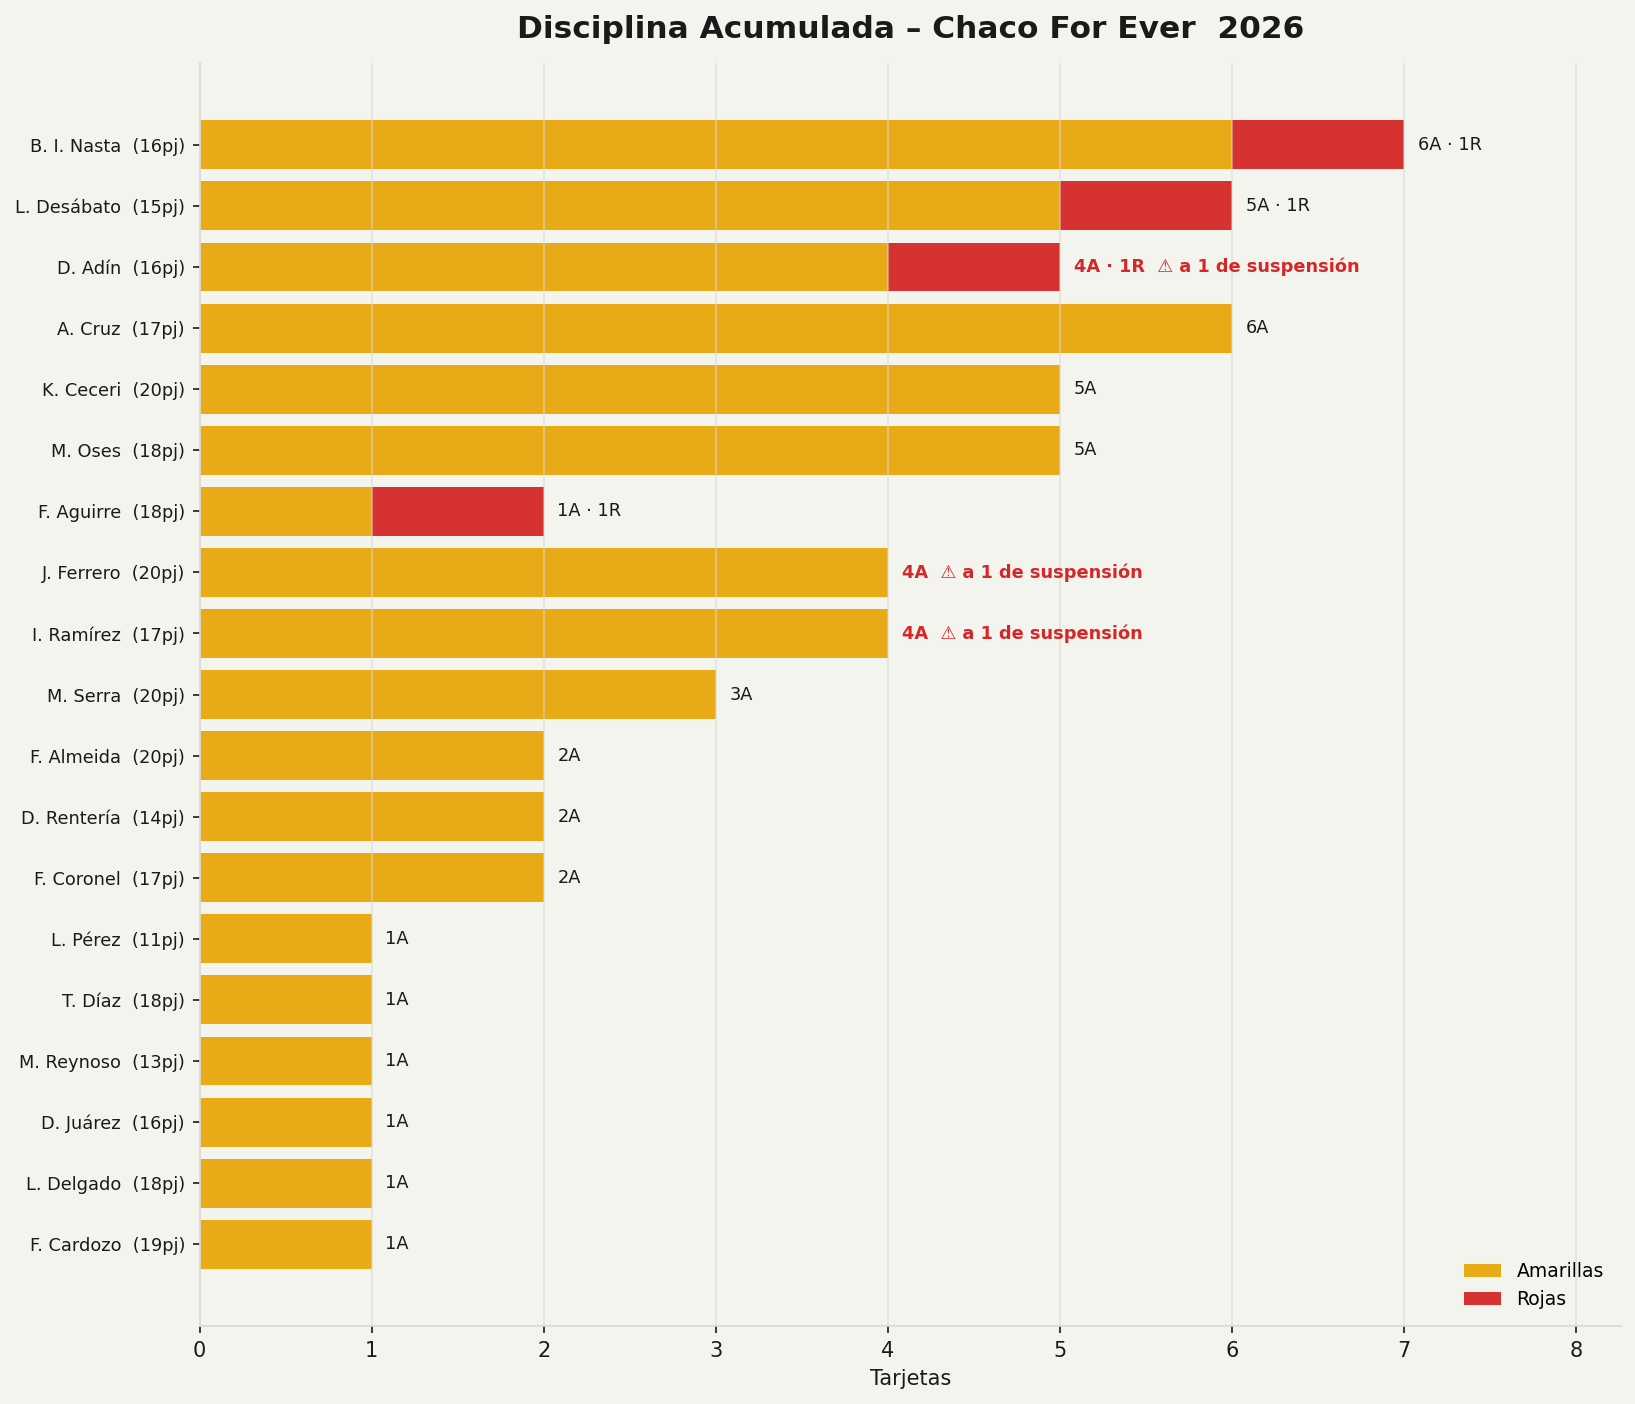

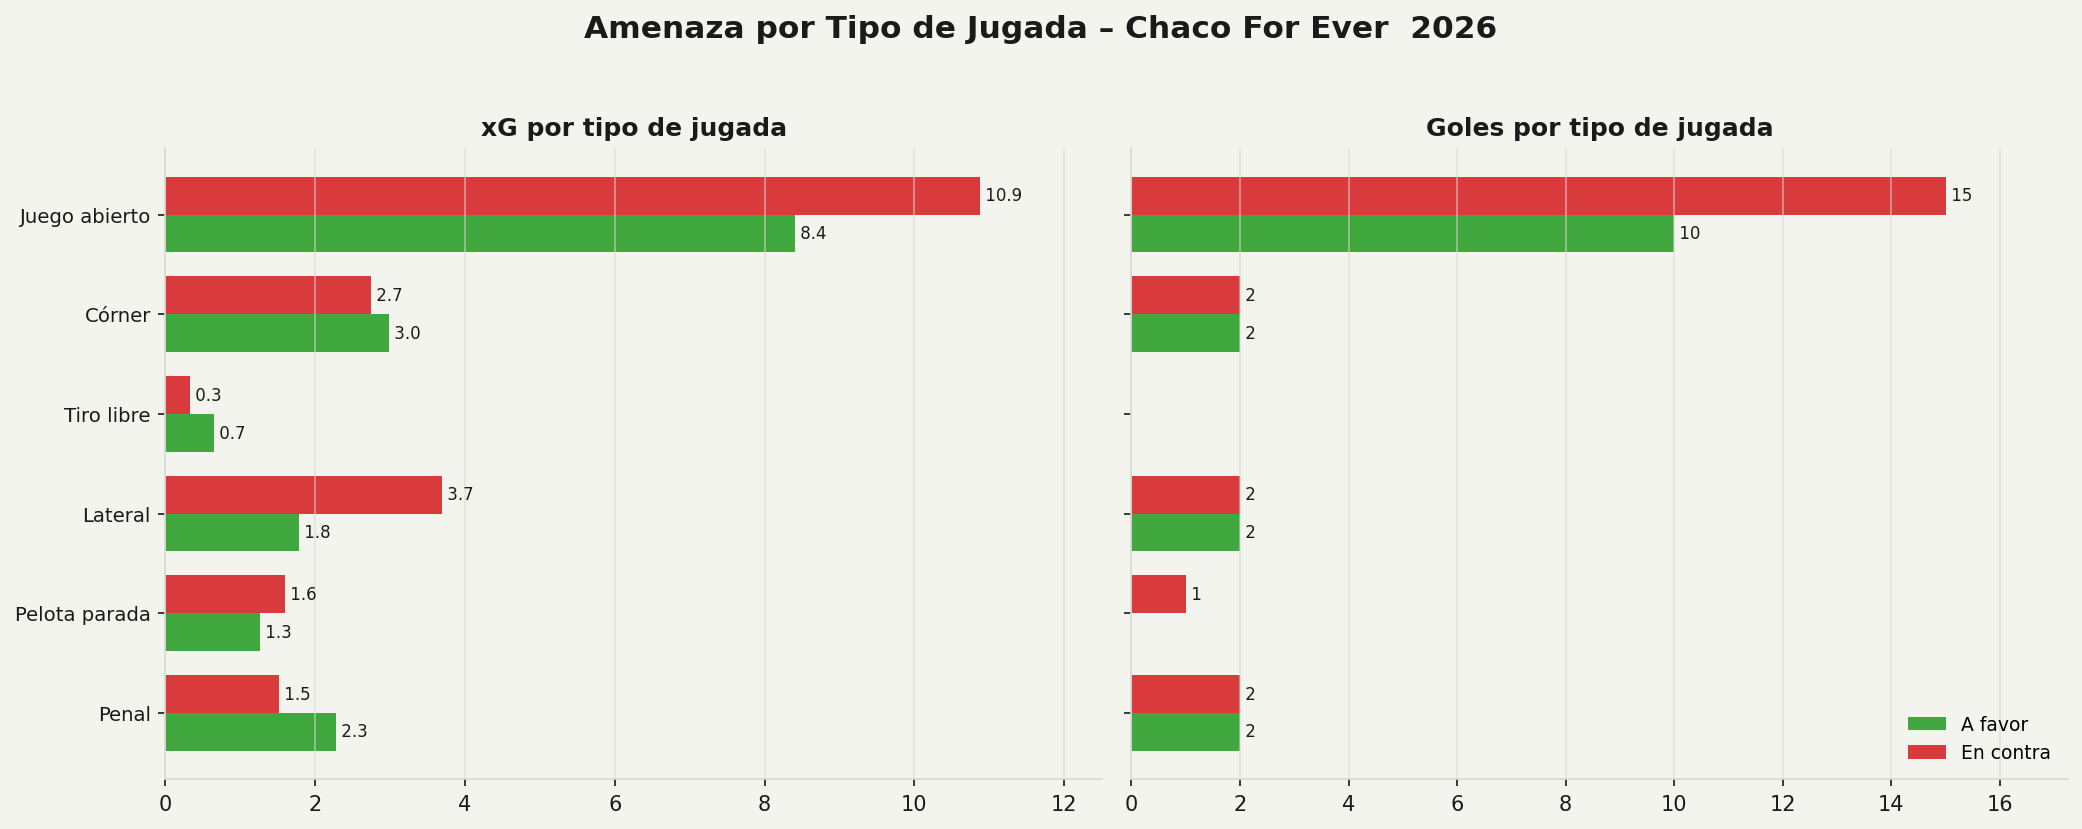

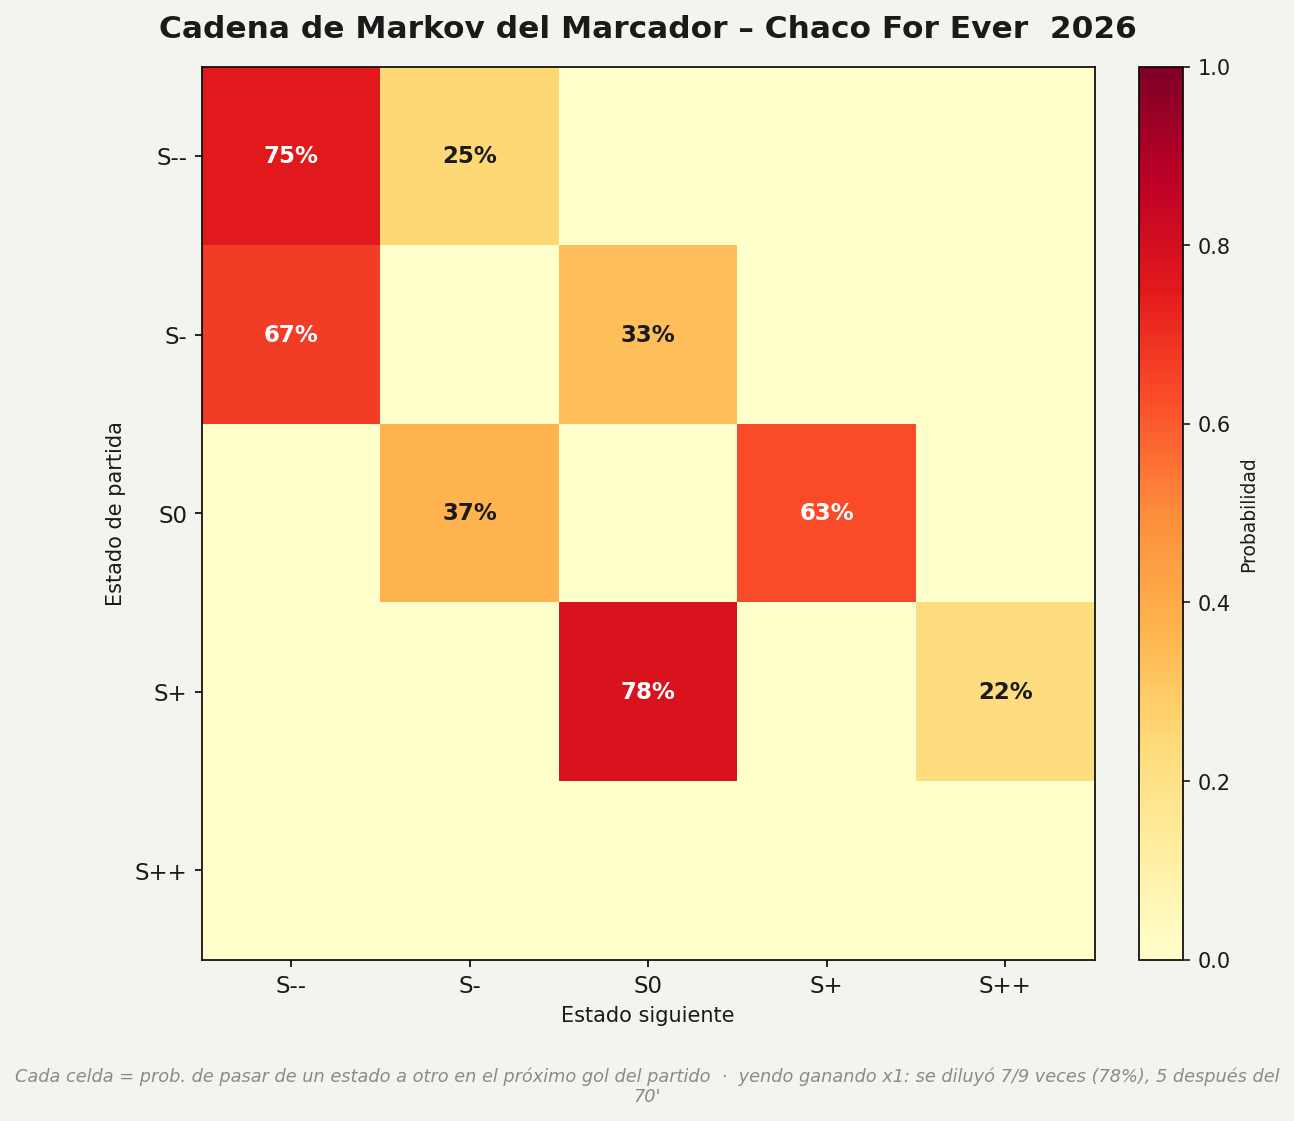

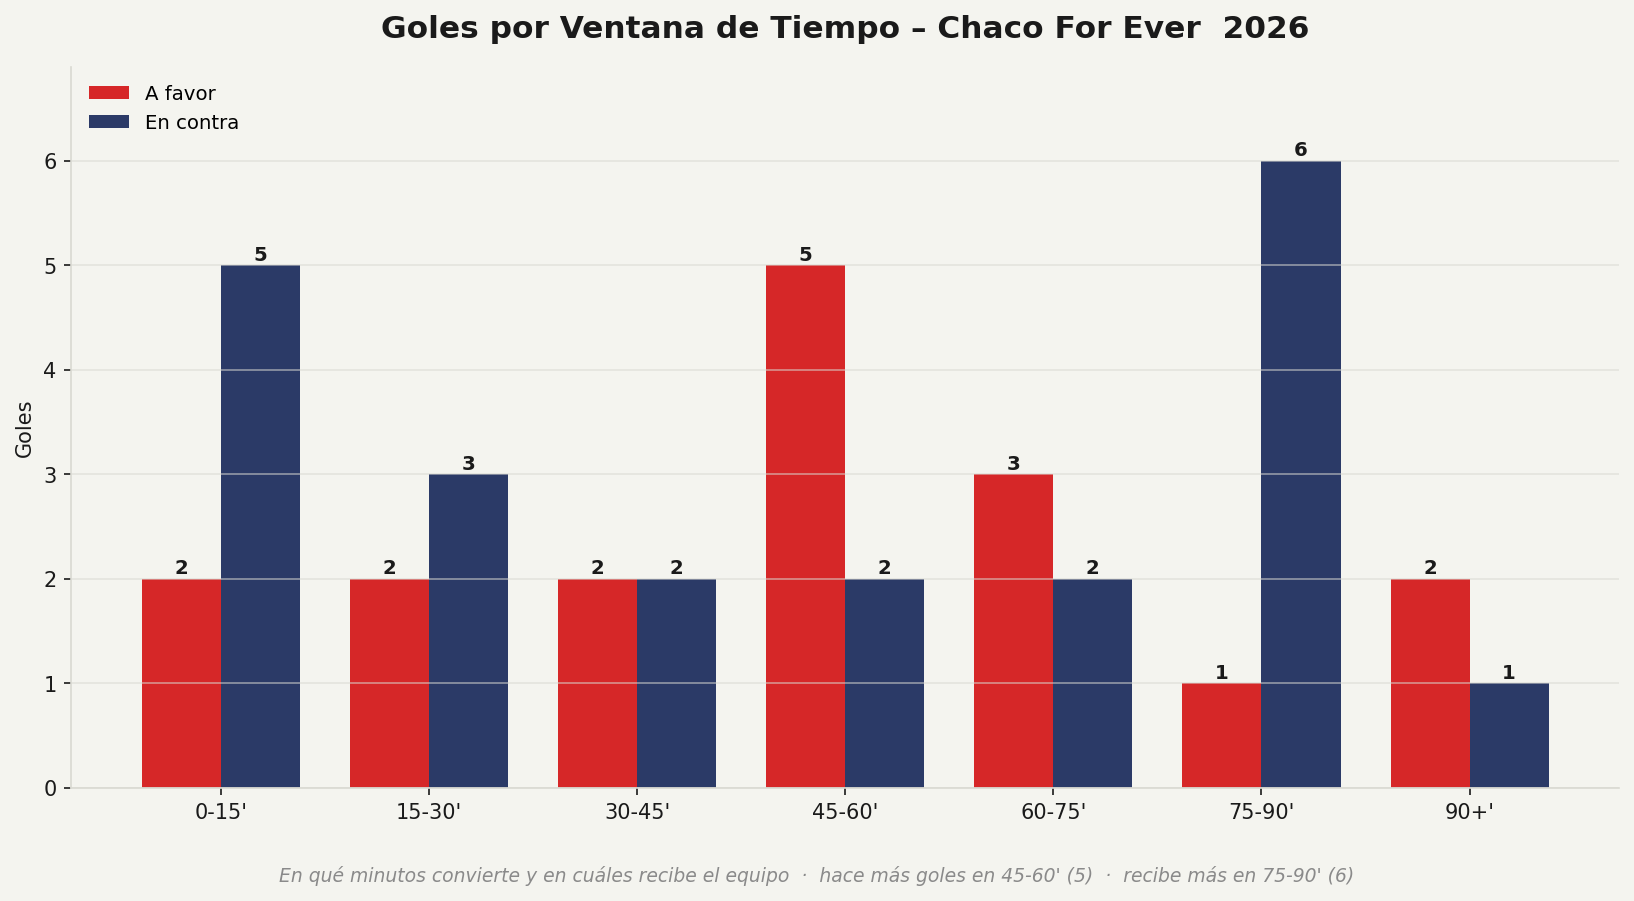

In [ ]:
EQUIPO_DETALLE = 'san_miguel'    # slug del proximo rival

nombre = config.RIVALS[EQUIPO_DETALLE]['name']
d = temporadas.get(EQUIPO_DETALLE)
if not d:
    stats, season_df, player_df = analisis_temporada_equipo(EQUIPO_DETALLE, SEASON)
else:
    stats, season_df, player_df = d['stats'], d['season_df'], d['player_df']

if stats:
    print(f"=== {nombre} · Temporada {SEASON} ===")
    print(f"{stats['partidos']} PJ | {stats['victorias']}V-{stats['empates']}E-{stats['derrotas']}D "
          f"| {stats['puntos']} pts")
    print(f"Goles: {stats['goles_favor']} a favor / {stats['goles_contra']} en contra")
    print(f"xG: {stats['xg_favor']} favor / {stats['xg_contra']} contra")
    print(f"Local: {stats['rendimiento_local']}  |  Visitante: {stats['rendimiento_visitante']}\n")
    print(season_df[['date', 'opponent', 'venue', 'result', 'chaco_goals', 'rival_goals']]
          .rename(columns={'chaco_goals': 'goles', 'rival_goals': 'goles_rival'})
          .to_string(index=False))

    if not player_df.empty:
        print('\n=== Goleadores ===')
        print(top_scorers(player_df).to_string(index=False))
        print('\n=== Mas utilizados ===')
        print(most_used_players(player_df).to_string(index=False))

    plots_dir = config.rival_plots_dir(EQUIPO_DETALLE, SEASON)
    for f in ['puntos_acumulados.png', 'xg_temporada.png', 'forma_reciente.png',
              'local_visitante.png', 'shotmap_temporada.png', 'top_minutos.png',
              'top_rating.png', 'disciplina.png', 'amenaza_por_situacion.png',
              'markov_estado_marcador.png', 'goles_por_ventana.png']:
        show(os.path.join(plots_dir, f))
